In [6]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils

from importlib import reload
utils = reload(utils)

## Utils

In [7]:
def evaluate_UC(UC, UC0=None):
    s = UC.get_s_pos()

    elemdata = UC.linopt4(at.All)[2]
    beta_x = elemdata.beta[:, 0]
    alpha_x = elemdata.alpha[:, 0]
    gamma_x = (1 + alpha_x**2)/beta_x
    D_x = elemdata.dispersion[:, 0]
    Dp_x = elemdata.dispersion[:, 1]

    H = gamma_x*D_x**2 + 2*alpha_x*D_x*Dp_x + beta_x * Dp_x**2
    fig, axs = plt.subplots(2, 1, figsize=(8, 8))

    # Main axis: Twiss parameters
    axs[0].plot(s, beta_x, label='$\\beta_x$ [m]')
    axs[0].plot(s, alpha_x, label='$\\alpha_x$')
    axs[0].plot(s, gamma_x, label='$\\gamma_x$ [1/m]')

    axs[0].set_xlabel('$s$ [m]')
    axs[0].set_ylabel('Twiss parameters')

    # Secondary axis: dispersion
    ax0_twin = axs[0].twinx()
    ax0_twin.plot(s, D_x, ls='--', label='$D_x$ [m]')
    ax0_twin.plot(s, Dp_x, ls='--', label='$D\'_x$')
    ax0_twin.set_ylabel('Dispersion')

    # Combine legends from both axes
    lines1, labels1 = axs[0].get_legend_handles_labels()
    lines2, labels2 = ax0_twin.get_legend_handles_labels()
    lines = lines1 + lines2
    labels = labels1 + labels2

    # H
    axs[1].plot(s, H, label='$H$')
    axs[1].plot(s, beta_x * Dp_x**2 / 10, ls='--',
                label='$\\beta_x D\'^2$ / 10')
    axs[1].plot(s, 2*alpha_x*D_x*Dp_x / 10, ls='--',
                label='$2 \\alpha_x D D\'$ / 10')
    axs[1].plot(s, gamma_x*D_x**2 / 10, ls='--',
                label='$\\gamma_x D^2$ / 10')

    axs[1].set_xlabel('$s$ [m]')
    axs[1].set_ylabel('$H$ [m]')

    # Titles
    rad_params = at.radiation_parameters(UC)
    
    axs[0].set_title(f'Unit cell tunes: {elemdata.mu[-1, 0] / (2*np.pi):.3f} {elemdata.mu[-1, 1] / (2*np.pi):.3f}')
    axs[1].set_title(f'$\\varepsilon_{{x, UC}}={rad_params.emittances[0]*1e12:.1f}$ pm rad ($J_x = {rad_params.J[0]:.1f}$)')

    axs[0].legend(lines, labels, ncols=10, loc='upper center')
    axs[1].legend(ncols=10, loc='upper center')

    axs[0].set_xticks(np.linspace(0, L_UC, 5))
    axs[1].set_xticks(np.linspace(0, L_UC, 5))

    Dmax = 1.05*max(abs(D_x).max(), abs(Dp_x).max())
    ax0_twin.set_ylim(-Dmax, Dmax)

    ymax = 1.05*max(abs(axs[0].get_ylim()[0]), abs(axs[0].get_ylim()[1]))
    axs[0].set_ylim(-ymax, ymax)
    

    axs[0].grid()
    axs[1].grid()

    at.plot_synopt(UC, axs[0])
    at.plot_synopt(UC, axs[1])

    fig.tight_layout()
    plt.show()

def get_H_integral(UC):
    s = UC.get_s_pos()

    elemdata = UC.linopt4(at.All)[2]
    beta_x = elemdata.beta[:, 0]
    alpha_x = elemdata.alpha[:, 0]
    gamma_x = (1 + alpha_x**2)/beta_x
    D_x = elemdata.dispersion[:, 0]
    Dp_x = elemdata.dispersion[:, 1]

    H = gamma_x*D_x**2 + 2*alpha_x*D_x*Dp_x + beta_x * Dp_x**2
    return scipy.integrate.trapezoid(H, s)

def get_dipole(FamName, L, angle, KL, D_shape, K_shape=None, plots=False):
    if K_shape is None:
        K_shape = D_shape
    
    s = np.linspace(0, L, len(D_shape)+1)
    l = L / len(D_shape)

    angle_dist = angle * (D_shape / np.sum(D_shape))
    K_dist = (KL/l) * (K_shape / np.sum(K_shape))

    if plots:
        fig, axs = plt.subplots(2, 1, sharex=True)
        axs[0].stairs(angle_dist/l, s)
        axs[1].stairs(K_dist, s)

        axs[0].set_ylabel('Bending strength [m$^{-1}$]')
        axs[1].set_ylabel('K [m$^{-2}$]')
        axs[1].set_xlabel('$s$ [m]')

        plt.tight_layout()
        plt.show()

    elements = []
    for theta, K in zip(angle_dist, K_dist):
        elements.append(at.Dipole(FamName, l, theta, K, FieldScaling=1.0))

    return elements

def set_PolynomB_scale(scaling, ring, refpts, PolynomB0):
    assert PolynomB0 != None

    for element, PolynomB in zip(ring[refpts], PolynomB0):
        element.PolynomB = scaling * PolynomB

def get_PolynomB_scale(ring, refpts, PolynomB0):
    scaling = []
    for element, PolynomB in zip(ring[refpts], PolynomB0):
        scaling = element.PolynomB / PolynomB

    return np.nanmean(scaling)

PolynomB_scale = (set_PolynomB_scale, get_PolynomB_scale)

## Load ring

In [8]:
with open('candidates/v01_01_03_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

In [9]:
s0 = ring0.get_s_pos()
index_UC0 = ring0.get_uint32_index('UCborder')

## Visualize ring

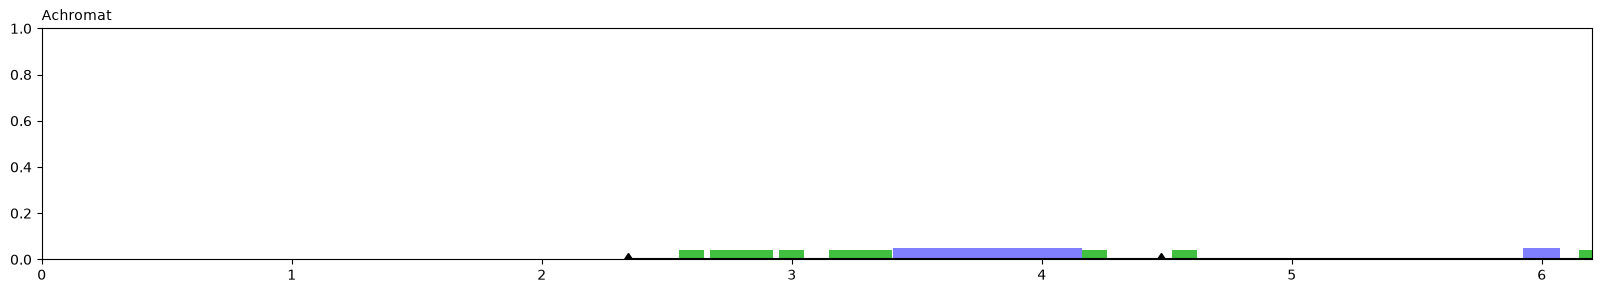

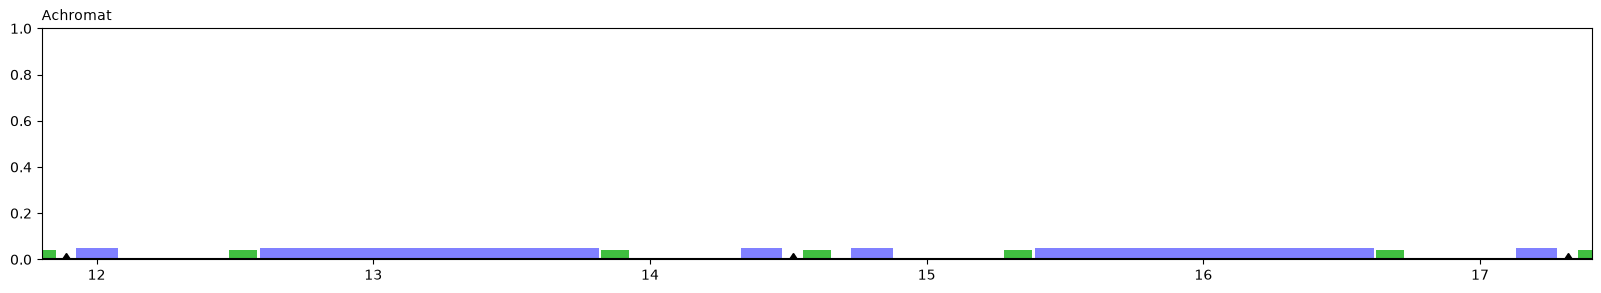

In [10]:
# Matching sections
fig, ax = plt.subplots(figsize=(20, 3))
at.plot_synopt(ring0, ax)
plt.xlim(0, s0[index_UC0[0]])
plt.show()

# Center unit cell
fig, ax = plt.subplots(figsize=(20, 3))
at.plot_synopt(ring0, ax)
plt.xlim(s0[index_UC0[2]], s0[index_UC0[4]])
plt.show()

## D2 profile

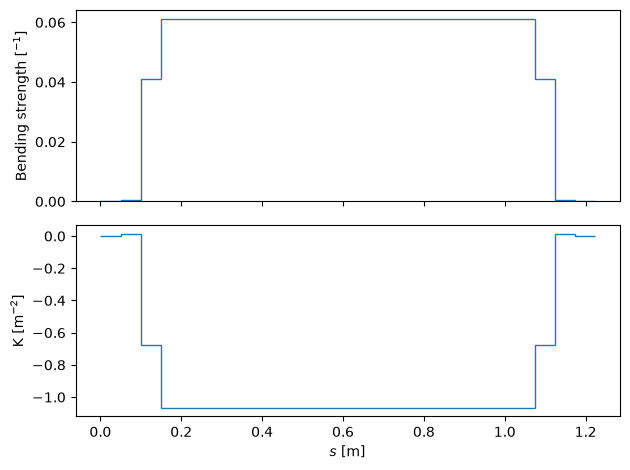

In [11]:
fig, axs = plt.subplots(2, 1, sharex=True)
    

D2 = ring0['D2_v1'][0:16]
s_D2 = at.get_s_pos(D2)

angle_dist = [e.BendingAngle/e.Length for e in D2]
K_dist = [e.PolynomB[1] for e in D2]

axs[0].stairs(angle_dist, s_D2)
axs[1].stairs(K_dist, s_D2)

axs[0].set_ylabel('Bending strength [$^{-1}$]')
axs[1].set_ylabel('K [m$^{-2}$]')
axs[1].set_xlabel('$s$ [m]')

plt.tight_layout()
plt.show()

In [12]:
for e in ring0[index_UC0[0]:index_UC0[1]]:
    print(f'{e.FamName} ({1e3*e.Length:.2f} mm)')

UCborder (0.00 mm)
S2_v1 (50.00 mm)
strx013 (12.50 mm)
bpm_d (25.00 mm)
BPM (0.00 mm)
bpm_d (25.00 mm)
strx013 (12.50 mm)
R1_v1 (150.00 mm)
str0100 (100.00 mm)
corr_d (25.00 mm)
corrv (0.00 mm)
corr_d (25.00 mm)
corr_d (25.00 mm)
corrh (0.00 mm)
corr_d (25.00 mm)
strx203 (203.11 mm)
S3_v1 (50.00 mm)
S3_v1 (50.00 mm)
str0010 (10.00 mm)
str3 (0.48 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (120.63 mm)
D2_v1 (120.63 mm)
D2_v1 (120.63 mm)
D2_v1 (120.63 mm)
D2_v1 (120.63 mm)
D2_v1 (120.63 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
D2_v1 (50.00 mm)
str3 (0.48 mm)
str0010 (10.00 mm)
S3_v1 (50.00 mm)
S3_v1 (50.00 mm)
strx403 (403.11 mm)
GE (0.00 mm)
GS (0.00 mm)
R1_v1 (150.00 mm)
str0075 (75.00 mm)
S4_v1 (50.00 mm)


## Original Unit Cell

In [13]:
UC0 = ring0[index_UC0[2]:index_UC0[3]]

# Dipole parameters
L0 = 2.01237 - 0.78859 - 0.2 # Remove fringe fields
theta0 = np.sum([e.BendingAngle for e in UC0['D2_v1']])
KL0 = np.sum([e.K*e.Length for e in UC0['D2_v1']])

# Other lengths and positions
L_UC = 2.80096 # Total length of UC
L_S3 = 0.1 # Total length of S3
L_corr = 0.025*4 # Total length of correctors

s_R1_start = 0.12500 # Start of R1
s_R1_end = 0.27500 # End of R1
s_corr_end = 0.12500 # End h / v corrector
s_D2_start = 0.78859 + 0.1 # Start of D2 (remove fringe fields)

## Simplified unit cell lattice

In [9]:
L = 0
for e in UC0:
    padding = 10 - len(e.FamName)
    print(f'{e.FamName}{padding*' '}{L:.5f} to {L+e.Length:.5f} m ({e.Length:.5f} m)')
    L += e.Length

UCborder  0.00000 to 0.00000 m (0.00000 m)
S4_v1     0.00000 to 0.05000 m (0.05000 m)
strx013   0.05000 to 0.06250 m (0.01250 m)
bpm_d     0.06250 to 0.08750 m (0.02500 m)
BPM       0.08750 to 0.08750 m (0.00000 m)
bpm_d     0.08750 to 0.11250 m (0.02500 m)
strx013   0.11250 to 0.12500 m (0.01250 m)
R1_v1     0.12500 to 0.27500 m (0.15000 m)
str0100   0.27500 to 0.37500 m (0.10000 m)
corr_d    0.37500 to 0.40000 m (0.02500 m)
corrv     0.40000 to 0.40000 m (0.00000 m)
corr_d    0.40000 to 0.42500 m (0.02500 m)
corr_d    0.42500 to 0.45000 m (0.02500 m)
corrh     0.45000 to 0.45000 m (0.00000 m)
corr_d    0.45000 to 0.47500 m (0.02500 m)
strx203   0.47500 to 0.67811 m (0.20311 m)
S3_v1     0.67811 to 0.72811 m (0.05000 m)
S3_v1     0.72811 to 0.77811 m (0.05000 m)
str0010   0.77811 to 0.78811 m (0.01000 m)
str3      0.78811 to 0.78859 m (0.00048 m)
D2_v1     0.78859 to 0.83859 m (0.05000 m)
D2_v1     0.83859 to 0.88859 m (0.05000 m)
D2_v1     0.88859 to 0.93859 m (0.05000 m)
D2_v1     0

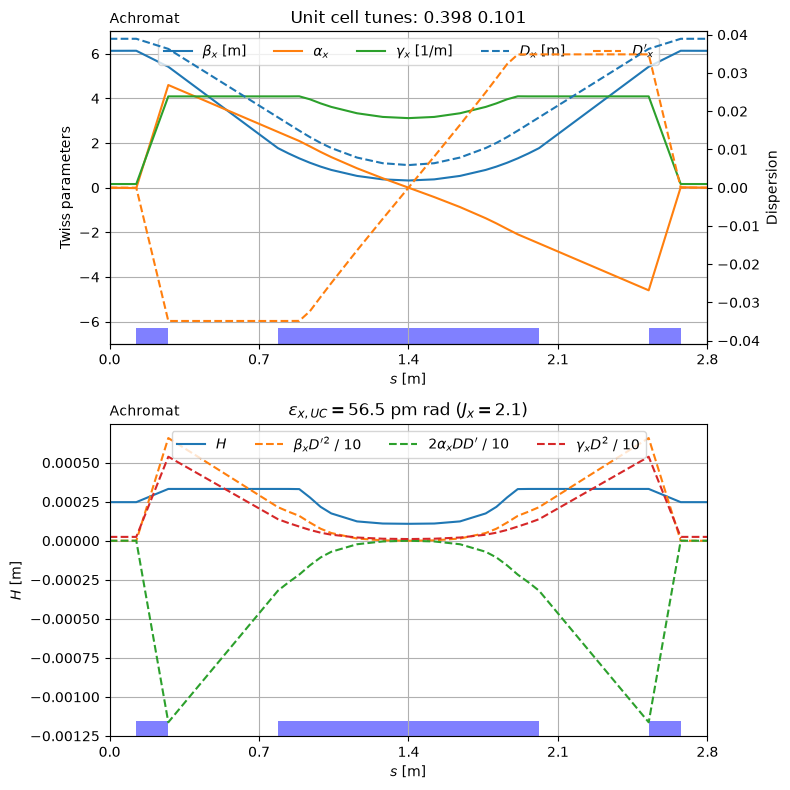

In [10]:
# Empty copy of UC0 (retains energy etc)
UC = deepcopy(UC0)
while len(UC) > 0: UC.remove(UC[0])

UC.append(at.Drift('str0', s_R1_start))
UC.append(deepcopy(UC0['R1_v1'][0]))
UC.append(at.Drift('str1', s_D2_start - s_R1_end - 0.1))

UC.extend(deepcopy(UC0['D2_v1']))

UC.append(at.Drift('str1', s_D2_start - s_R1_end - 0.1))
UC.append(deepcopy(UC0['R1_v1'][1]))
UC.append(at.Drift('str0', 0.12500))

if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
    print(f'Wrong UC length! (Diff {L_UC - UC.get_s_pos(at.End)[0]} m)')

evaluate_UC(UC)

## New dipole shape

In [ ]:
# Empty copy of UC0 (retains energy etc)
UC = deepcopy(UC0)
while len(UC) > 0: UC.remove(UC[0])

UC.append(at.Drift('str0', s_R1_start))
UC.append(deepcopy(UC0['R1_v1'][0]))
UC.append(at.Drift('str1', s_D2_start - s_R1_end))

x = np.linspace(-1, 1, 42)
D_shape = np.exp(-5*x**2)
K_shape = np.exp(-10*x**2)
D2_new = get_dipole('D2_v1', L0, theta0, KL0, D_shape, K_shape, plots=True)
UC.extend(D2_new)

UC.append(at.Drift('str1', s_D2_start - s_R1_end))
UC.append(deepcopy(UC0['R1_v1'][1]))
UC.append(at.Drift('str0', s_R1_start))

if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
    print(f'Wrong UC length! (Diff of {L_UC - UC.get_s_pos(at.End)[0]} m)')

evaluate_UC(UC)

In [ ]:
# Empty copy of UC0 (retains energy etc)
UC = deepcopy(UC0)
while len(UC) > 0: UC.remove(UC[0])

UC.append(at.Drift('str0', s_R1_start))
UC.append(deepcopy(UC0['R1_v1'][0]))
UC.append(at.Drift('str1', s_D2_start - s_R1_end))

x = np.linspace(-1, 1, 42)
D_shape = np.exp(-5*x**2)
K_shape = np.exp(-3*x**2)
D2_new = get_dipole('D2_v1', L0, theta0, KL0, D_shape, K_shape, plots=True)
UC.extend(D2_new)

UC.append(at.Drift('str1', s_D2_start - s_R1_end))
UC.append(deepcopy(UC0['R1_v1'][1]))
UC.append(at.Drift('str0', s_R1_start))

if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
    print(f'Wrong UC length! (Diff of {L_UC - UC.get_s_pos(at.End)[0]} m)')

vars = at.VariableList([
    at.CustomVariable(*PolynomB_scale, name='R1 scale', delta=1e-3, ring=UC, refpts='R1_v1', PolynomB0=[e.PolynomB for e in UC['R1_v1']]),
    at.CustomVariable(*PolynomB_scale, name='D2 scale', delta=1e-3, ring=UC, refpts='D2_v1', PolynomB0=[e.PolynomB for e in UC['D2_v1']]),
])

obs = at.ObservableList([
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*0.4),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*0.1),
])

UC.match(vars, obs, verbose=2)

evaluate_UC(UC)

## Optimizing field profile

In [11]:
N = 20
sigma_D, sigma_K = np.meshgrid(np.linspace(0, 10, N), np.linspace(-10, 10, N))

emittance = np.zeros_like(sigma_D)
for i, j in np.ndindex(sigma_D.shape):
    # Empty copy of UC0 (retains energy etc)
    UC = deepcopy(UC0)
    while len(UC) > 0: UC.remove(UC[0])

    UC.append(at.Drift('str0', s_R1_start))
    UC.append(deepcopy(UC0['R1_v1'][0]))
    UC.append(at.Drift('str1', s_D2_start - s_R1_end))

    x = np.linspace(-1, 1, 42)
    D_shape = np.exp(-sigma_D[i, j]*x**2)
    K_shape = np.exp(-sigma_K[i, j]*x**2)
    D2_new = get_dipole('D2_v1', L0, theta0, KL0, D_shape, K_shape)
    UC.extend(D2_new)

    UC.append(at.Drift('str1', s_D2_start - s_R1_end))
    UC.append(deepcopy(UC0['R1_v1'][1]))
    UC.append(at.Drift('str0', s_R1_start))

    if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
        print(f'Wrong UC length! (Diff of {L_UC - UC.get_s_pos(at.End)[0]} m)')

    vars = at.VariableList([
        at.CustomVariable(*PolynomB_scale, name='R1 scale', delta=1e-3, ring=UC, refpts='R1_v1', PolynomB0=[e.PolynomB for e in UC['R1_v1']]),
        at.CustomVariable(*PolynomB_scale, name='D2 scale', delta=1e-3, ring=UC, refpts='D2_v1', PolynomB0=[e.PolynomB for e in UC['D2_v1']]),
    ])

    obs = at.ObservableList([
        at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*0.4),
        at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*0.1),
    ])

    try:
        UC.match(vars, obs, verbose=0)
        emittance[i, j] = at.radiation_parameters(UC).emittances[0]*1e12
    except Exception as e:
        print(e)
        emittance[i, j] = np.nan

Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstable ring
Evaluation of mu[x] failed: Unstab

In [13]:
from utils.plotting import meshgrid_extent

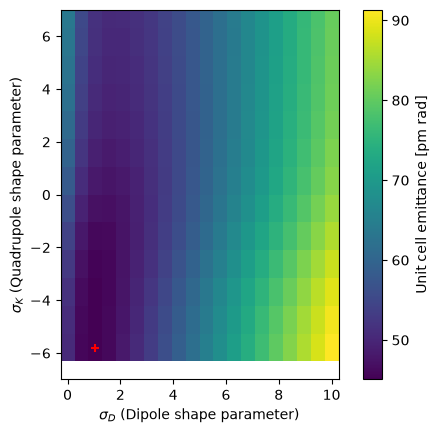

In [14]:
extent = meshgrid_extent(sigma_D, sigma_K, 'upper')
plt.imshow(emittance, extent=extent, origin='lower')
plt.xlabel('$\\sigma_D$ (Dipole shape parameter)')
plt.ylabel('$\\sigma_K$ (Quadrupole shape parameter)')
cax = plt.colorbar()
cax.set_label('Unit cell emittance [pm rad]')

i = np.argmin(emittance[np.isfinite(emittance)])
sigma_D_opt = sigma_D[np.isfinite(emittance)][i]
sigma_K_opt = sigma_K[np.isfinite(emittance)][i]
plt.ylim(-7, 7)

plt.scatter(sigma_D_opt, sigma_K_opt, marker='+', c='red')
plt.show()

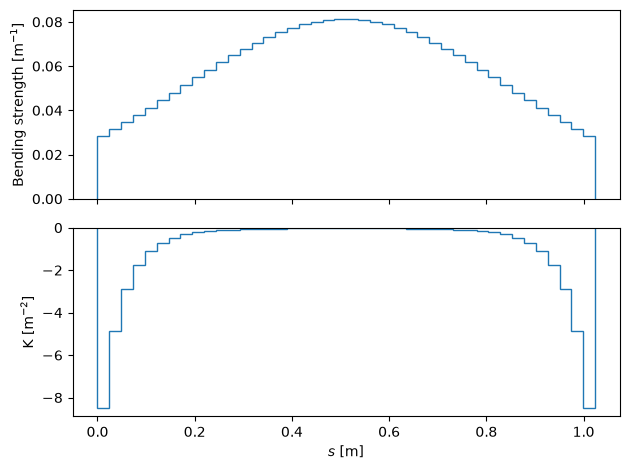


2 constraints, 2 variables, using method lm

`xtol` termination condition is satisfied.
Function evaluations 7, initial cost 1.7421e-01, final cost 4.2956e-30, first-order optimality 7.85e-15.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
mu[x]
    End                   2.29857           2.51327           2.51327           2.51327      -8.64964e-09 
mu[y]
    End                 0.0784867          0.628319          0.628319          0.628319       6.29604e-08 

Variables:

        Name      Initial          Final        Variation

    R1 scale    1.000000e+00    1.064259e+00    6.425855e-02
    D2 scale    1.000000e+00    1.123571e+00    1.235715e-01


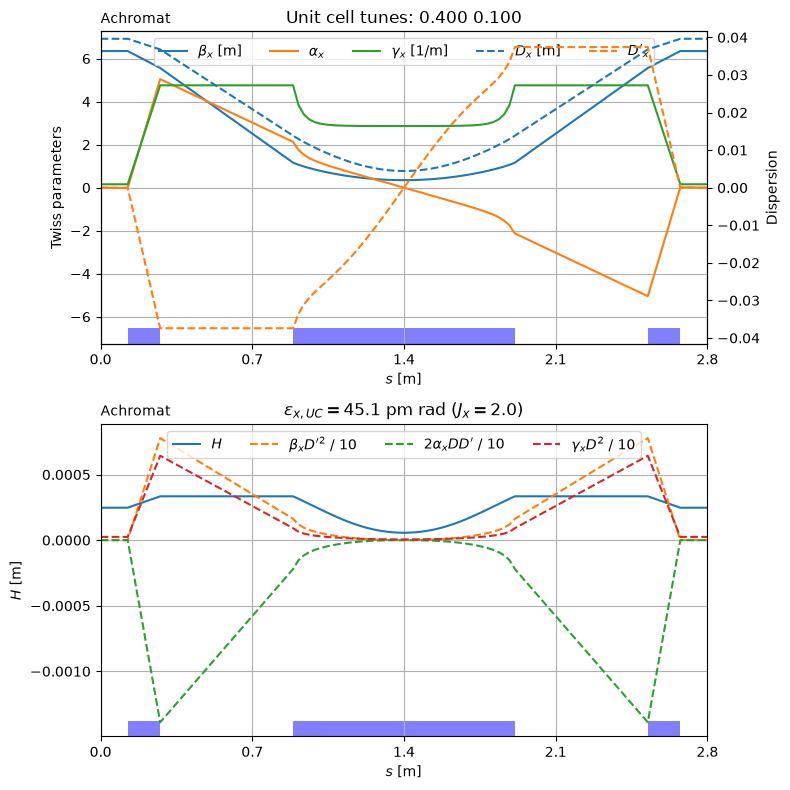

In [15]:
# Empty copy of UC0 (retains energy etc)
UC = deepcopy(UC0)
while len(UC) > 0: UC.remove(UC[0])

UC.append(at.Drift('str0', s_R1_start))
UC.append(deepcopy(UC0['R1_v1'][0]))
UC.append(at.Drift('str1', s_D2_start - s_R1_end))

x = np.linspace(-1, 1, 42)
D_shape = np.exp(-sigma_D_opt*x**2)
K_shape = np.exp(-sigma_K_opt*x**2)
D2_new = get_dipole('D2_v1', L0, theta0, KL0, D_shape, K_shape, plots=True)
UC.extend(D2_new)

UC.append(at.Drift('str1', s_D2_start - s_R1_end))
UC.append(deepcopy(UC0['R1_v1'][1]))
UC.append(at.Drift('str0', s_R1_start))

if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
    print(f'Wrong UC length! (Diff of {L_UC - UC.get_s_pos(at.End)[0]} m)')

vars = at.VariableList([
    at.CustomVariable(*PolynomB_scale, name='R1 scale', delta=1e-3, ring=UC, refpts='R1_v1', PolynomB0=[e.PolynomB for e in UC['R1_v1']]),
    at.CustomVariable(*PolynomB_scale, name='D2 scale', delta=1e-3, ring=UC, refpts='D2_v1', PolynomB0=[e.PolynomB for e in UC['D2_v1']]),
])

obs = at.ObservableList([
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*0.4),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*0.1),
])

UC.match(vars, obs, verbose=2)

evaluate_UC(UC)

## Change reverse bends

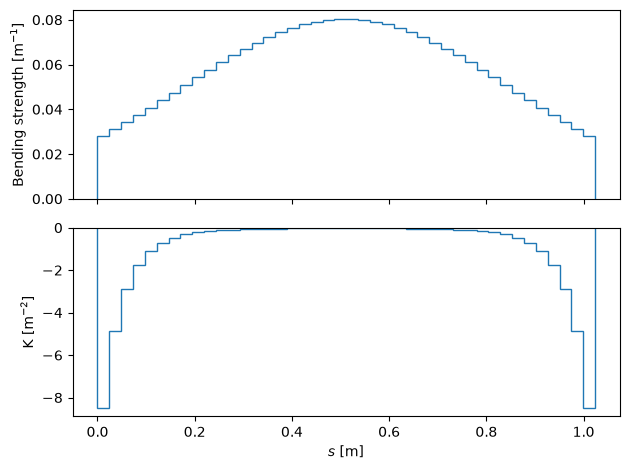


2 constraints, 2 variables, using method lm

`xtol` termination condition is satisfied.
Function evaluations 7, initial cost 1.7423e-01, final cost 2.0954e-30, first-order optimality 5.16e-15.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
mu[x]
    End                   2.29846           2.51327           2.51327           2.51327      -8.64996e-09 
mu[y]
    End                 0.0784867          0.628319          0.628319          0.628319       6.29619e-08 

Variables:

        Name      Initial          Final        Variation

    R1 scale    1.000000e+00    1.064284e+00    6.428437e-02
    D2 scale    1.000000e+00    1.123586e+00    1.235864e-01


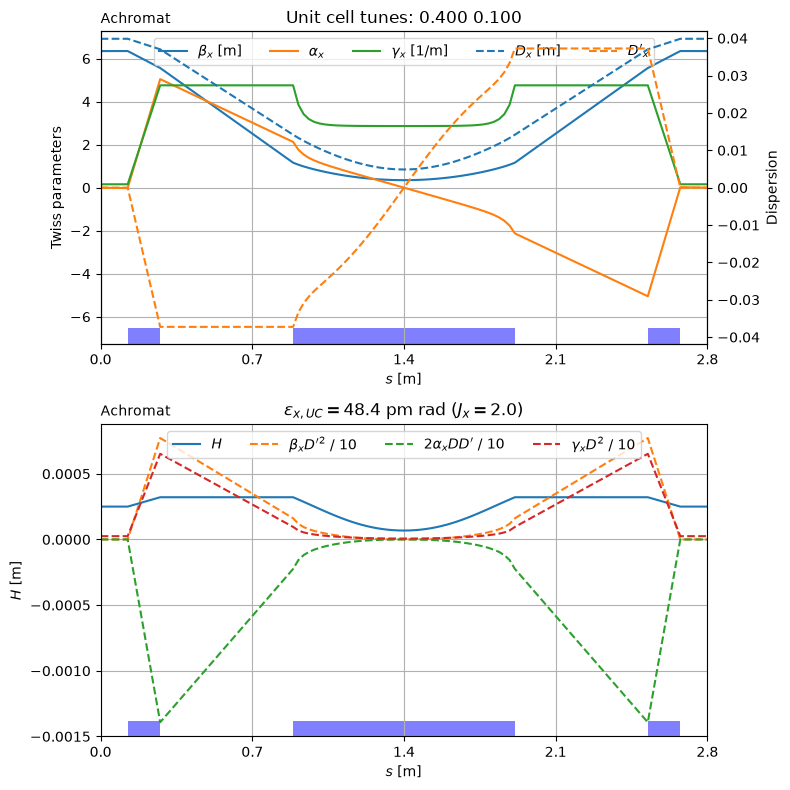

In [16]:
dtheta = -0.1 * abs(UC0['R1_v1'][0].BendingAngle)

# Empty copy of UC0 (retains energy etc)
UC = deepcopy(UC0)
while len(UC) > 0: UC.remove(UC[0])

UC.append(at.Drift('str0', s_R1_start))
UC.append(deepcopy(UC0['R1_v1'][0]))
UC.append(at.Drift('str1', s_D2_start - s_R1_end))

x = np.linspace(-1, 1, 42)
D_shape = np.exp(-sigma_D_opt*x**2)
K_shape = np.exp(-sigma_K_opt*x**2)
D2_new = get_dipole('D2_v1', L0, theta0 + 2*dtheta, KL0, D_shape, K_shape, plots=True)
UC.extend(D2_new)

UC.append(at.Drift('str1', s_D2_start - s_R1_end))
UC.append(deepcopy(UC0['R1_v1'][1]))
UC.append(at.Drift('str0', s_R1_start))

for e in UC['R1_v1']:
    e.BendingAngle -= dtheta

if abs(L_UC - UC.get_s_pos(at.End)[0]) > 1e-9:
    print(f'Wrong UC length! (Diff of {L_UC - UC.get_s_pos(at.End)[0]} m)')

vars = at.VariableList([
    at.CustomVariable(*PolynomB_scale, name='R1 scale', delta=1e-3, ring=UC, refpts='R1_v1', PolynomB0=[e.PolynomB for e in UC['R1_v1']]),
    at.CustomVariable(*PolynomB_scale, name='D2 scale', delta=1e-3, ring=UC, refpts='D2_v1', PolynomB0=[e.PolynomB for e in UC['D2_v1']]),
])

obs = at.ObservableList([
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*0.4),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*0.1),
])

UC.match(vars, obs, verbose=2)

evaluate_UC(UC)

## Full ring

In [51]:
ring = utils.at.replace_family(ring0, 'D2_v1', UC0['D2_v1'], pad=True)
ring = utils.at.replace_family(ring, 'R1_v1', UC0['R1_v1'][0], pad=True)
index_UC = ring.get_uint32_index('UCborder')
UC_elemdata0 = at.linopt4(UC)[0]

# For scaling D1 strengths
D1_refpts = ring.uint32_refpts('D1_v1')
D1_K0 = np.array([ring[i].K for i in D1_refpts])

goal_tune = np.array([58.3202, 18.1676]) # TDR-1

def set_D1_scale(value):
    for i, K0 in zip(D1_refpts, D1_K0):
        ring[i].K = value* K0

def get_D1_scale(**kwargs):
    return ring[D1_refpts[0]].K / D1_K0[0]

vars = at.VariableList([
    at.CustomVariable(set_D1_scale, get_D1_scale, name='D1 scale', delta=1e-3),
    at.RefptsVariable('Q1_v1', attrname='K', name='Q1', delta=1e-5),
    at.RefptsVariable('Q2_v1', attrname='K', name='Q2', delta=1e-5),
    at.RefptsVariable('Q3_v1', attrname='K', name='Q2', delta=1e-5),
])

obs = at.ObservableList([
    # Unit cell Twiss matching
    at.LocalOpticsObservable(index_UC, 'alpha', plane='x', target=0, weight=1/len(index_UC)),
    at.LocalOpticsObservable(index_UC, 'alpha', plane='y', target=0, weight=1/len(index_UC)),

    # Unit cell dispersion matching
    at.LocalOpticsObservable(index_UC, 'dispersion', plane=0, target=UC_elemdata0.dispersion[0], weight=1/len(index_UC)),

    # Goal tune
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*goal_tune[0]/20),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*goal_tune[1]/20),

    # Dispersion in long straights
    at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
    at.LocalOpticsObservable(0, 'dispersion', plane=1, target=0),
])

ring.match(vars, obs, verbose=2)

print(at.radiation_parameters(ring).emittances[0])


22 constraints, 4 variables, using method lm

`ftol` termination condition is satisfied.
Function evaluations 7, initial cost 1.1364e-02, final cost 9.2968e-03, first-order optimality 2.17e-06.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
alpha[x]
    UCborder          5.53905e-09      -0.000129915               0.0               0.0      -0.000129915 
    UCborder         -6.64183e-08        0.00155157               0.0               0.0        0.00155157 
    UCborder         -4.26171e-08       0.000995817               0.0               0.0       0.000995817 
    UCborder          4.26312e-08      -0.000995817               0.0               0.0      -0.000995817 
    UCborder          6.64228e-08       -0.00155157               0.0               0.0       -0.00155157 
    UCborder         -5.56172e-09       0.000129915               0.0               0.0       0.000129915 
alpha[y]
    UCborder          1

In [ ]:
elemdata0 = ring0.linopt4(at.All)[2]
elemdata = ring.linopt4(at.All)[2]

print(f'{ring0.radiation_parameters().emittances[0]*1e12:.1f}')
print(f'{ring.radiation_parameters().emittances[0]*1e12:.1f}')

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.beta)
axs[1].plot(elemdata.s_pos, elemdata.beta)
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$\\beta$ [m]')
plt.show()

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.dispersion[:, 0])
axs[1].plot(elemdata.s_pos, elemdata.dispersion[:, 0])
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$D$ [m]')
plt.show()

## Free-form optimization

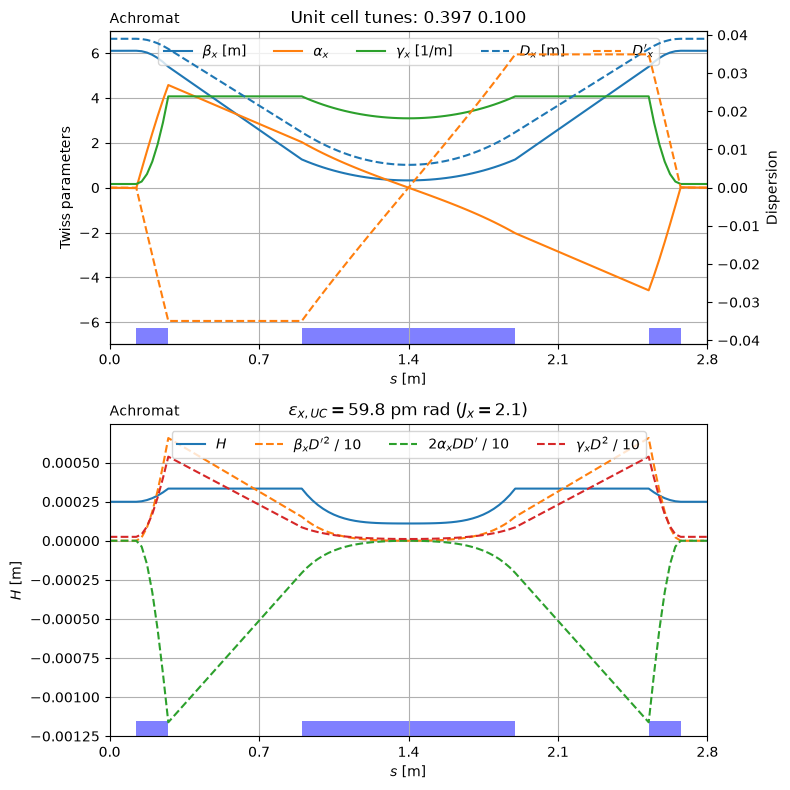

In [226]:
def simplified_UC(UC0, n_R=6, n_D=20, L_R=0.15, L_D=1.0):
    """
    Construct a simplified unit cell.
    """

    """ Basic parameters to conserve """
    # Lengths
    L_UC = UC0.get_s_pos()[-1]
    L_outer = UC0.get_s_pos('R1_v1')[0]
    L_inner = (L_UC - L_D - 2*L_R - 2*L_outer) / 2

    # Angles
    theta_R = np.sum([e.BendingAngle for e in UC0['R1_v1']]) / 2 # Only one of the reverse bends
    theta_D = np.sum([e.BendingAngle for e in UC0['D2_v1']])

    # Total quadrupole strengths
    KL_R = np.sum([e.K*e.Length for e in UC0['R1_v1']]) / 2 # Only one of the reverse bends
    KL_D = np.sum([e.K*e.Length for e in UC0['D2_v1']])


    """ Create slices """
    R_slice = deepcopy(UC0['R1_v1'][0])
    R_slice.Length = L_R/n_R
    R_slice.BendingAngle = theta_R / n_R
    R_slice.K = KL_R / L_R
    R_slices = [deepcopy(R_slice) for i in range(n_R)]

    D_slice = deepcopy(UC0['D2_v1'][0])
    D_slice.Length = L_D / (2*n_D)
    D_slice.BendingAngle = theta_D / (2*n_D)
    D_slice.K = KL_D / L_D
    D_slices = [deepcopy(D_slice) for i in range(n_D)]


    """ Creating lattice """
    # Empty copy of UC0 (retains energy etc)
    UC = deepcopy(UC0)
    while len(UC) > 0: UC.remove(UC[0])

    UC.append(at.Drift('drift_outer', L_outer))
    UC.extend(R_slices)
    UC.append(at.Drift('drift_inner', L_inner))

    UC.extend(D_slices)
    UC.extend(D_slices[::-1])

    UC.append(at.Drift('drift_inner', L_inner))
    UC.extend(R_slices[::-1])
    UC.append(at.Drift('drift_outer', L_outer))

    return UC

def set_UC_fields(UC, rho_inv, K):
    """
    Set the bending angles and K values of each of the slices in the UC
    """

    assert 2*len(rho_inv) == 2*len(K) == len(UC['R1_v1']) + len(UC['D2_v1'])
    n_R = len(UC['R1_v1']) // 2
    n_D = len(UC['D2_v1']) // 2
    R_slices = UC['R1_v1'][:n_R]
    D_slices = UC['D2_v1'][:n_D]

    for element, _rho_inv, _K in zip(R_slices + D_slices, rho_inv, K):
        element.BendingAngle = _rho_inv * element.Length
        element.K = _K

def get_UC_fields(UC):
    """
    Get the bending angles and K values of each of the slices in the UC
    """

    n_R = len(UC['R1_v1']) // 2
    n_D = len(UC['D2_v1']) // 2
    R_slices = UC['R1_v1'][:n_R]
    D_slices = UC['D2_v1'][:n_D]

    rho_inv = [element.BendingAngle / element.Length for element in R_slices + D_slices]
    K = [element.K for element in R_slices + D_slices]
    return rho_inv, K

def get_UC_x(UC):
    rho_inv, K = get_UC_fields(UC)
    L_inner = UC['drift_inner'][0].Length
    
    return np.array([L_inner, *rho_inv, *K])

UC_simple = simplified_UC(UC0)

evaluate_UC(UC_simple)

In [262]:
def smoothness_penalty(x):
    """Return the sum of local maximum and minimum prominence penalties."""
    x = np.asarray(x)

    maxima = np.maximum(
        x[1:-1] - np.maximum(x[:-2], x[2:]),
        0
    )

    minima = np.maximum(
        np.minimum(x[:-2], x[2:]) - x[1:-1],
        0
    )

    return np.sum(maxima + minima)

def loss(x, UC):
    L_inner = x[0]
    rho_inv = x[1:][:len(x[1:])//2]
    K = x[1:][len(x[1:])//2:]

    # Set drift length
    for e in UC['drift_inner']:
        e.Length = L_inner

    # Set fields
    set_UC_fields(UC, rho_inv, K)


    try:
        emittance = 1e12 * UC.radiation_parameters().emittances[0]
    except Exception as e:
        return 1000

    """ Smoothness penalties """
    n_R = len(UC['R1_v1'])//2

    # Normalized shape functions by magnet
    x_rho_R = rho_inv[:n_R]/np.mean(np.abs(rho_inv[:n_R]))
    x_rho_D = rho_inv[n_R:]/np.mean(np.abs(rho_inv[n_R:]))

    x_K_R = K[:n_R]/np.mean(np.abs(K[:n_R]))
    x_K_D = K[n_R:]/np.mean(np.abs(K[n_R:]))
    
    emittance += smoothness_penalty(x_rho_R)
    emittance += smoothness_penalty(x_rho_D)
    emittance += smoothness_penalty(x_K_R)
    emittance += smoothness_penalty(x_K_D)

    # emittance += np.max(np.abs(np.diff(x_rho_R))) * n_R
    # emittance += np.max(np.abs(np.diff(x_rho_D))) * n_D
    # emittance += np.max(np.abs(np.diff(x_K_R))) * n_R
    # emittance += np.max(np.abs(np.diff(x_K_D))) * n_D

    # print(np.max(np.abs(np.diff(x_rho_R))) * n_R)
    # print(np.max(np.abs(np.diff(x_rho_D))) * n_D)
    # print(np.max(np.abs(np.diff(x_K_R))) * n_R)
    # print(np.max(np.abs(np.diff(x_K_D))) * n_D)
    
    return emittance

def constraints(x, UC):
    L_inner = x[0]
    angles = x[1:][:len(x[1:])//2]
    K_values = x[1:][len(x[1:])//2:]

    # Set drift length
    for e in UC['drift_inner']:
        e.Length = L_inner

    # Set fields
    set_UC_fields(UC, angles, K_values)

    # Geometric constraints
    geometry = UC.get_geometry(at.End)[0]
    x_end = geometry.x[0]
    theta_UC = geometry.angle[0]

    # Phase
    UC_tunes = UC.linopt4(at.End)[2].mu[0] / (2*np.pi)

    return x_end, theta_UC, *UC_tunes

def constraint_fun(x, UC):
    return np.asarray(constraints(x, UC)) - np.array([
        UC0.get_geometry(at.End)[0].x[0],
        UC0.get_geometry(at.End)[0].angle[0],
        0.4,
        0.1,
    ])

In [252]:
ratio = np.array([1.0, 1.1, 1.2, 1.3, 1.4, 1.5])
# ratio = np.array([1.1, 1.2, 1.3])
UC_opt = []
for r_max in ratio:
    print(r_max)
    r = np.array([0, r_max])
    bounds = [(None, None)] + [(*np.sort(r*x),) for x in get_UC_x(UC_simple)[1:]]

    UC_opt.append(deepcopy(UC_simple))
    result = scipy.optimize.minimize(
        loss,
        get_UC_x(UC_simple),
        args=(UC_opt[-1],),
        constraints={
            'type': 'eq',
            'fun': constraint_fun,
            'args': (UC_opt[-1],),
        },
        bounds = bounds
    )

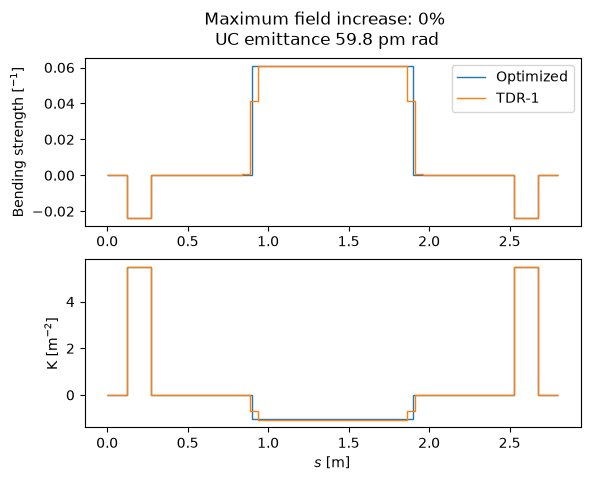

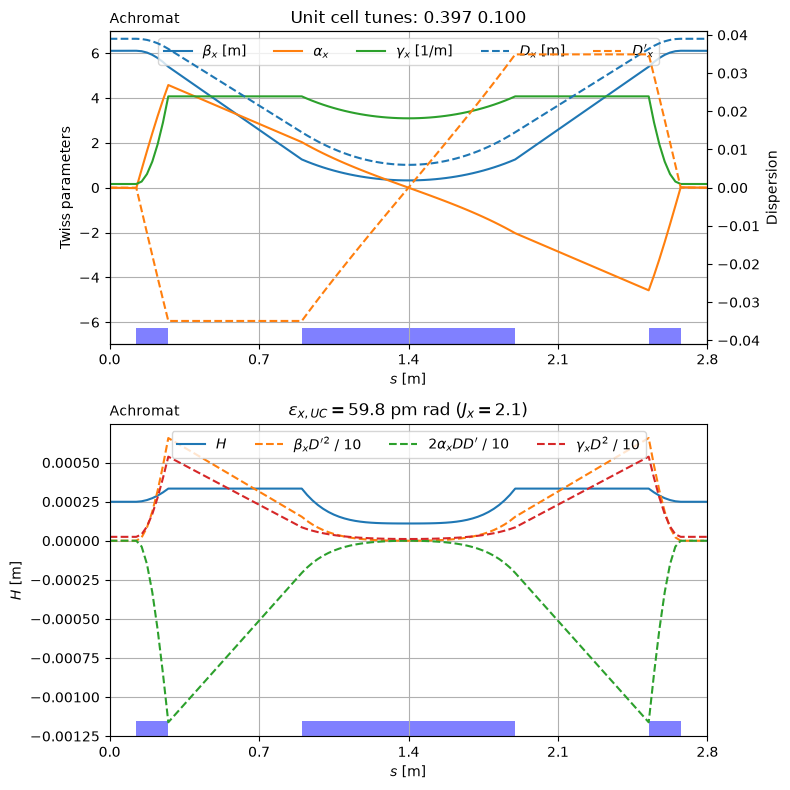

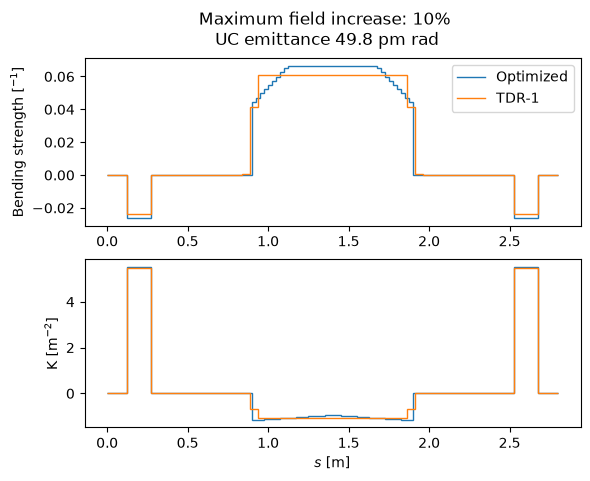

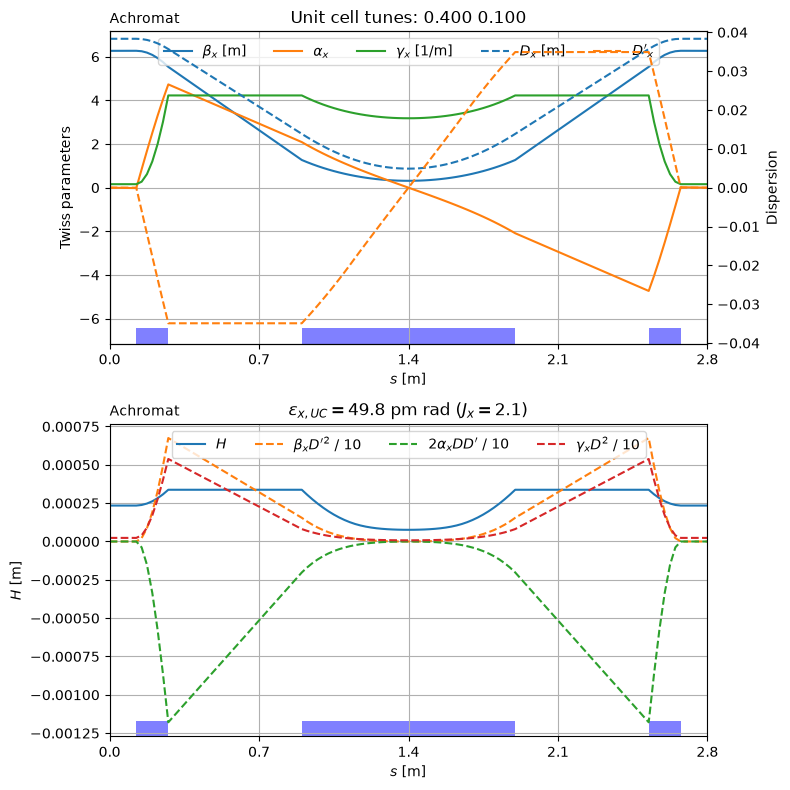

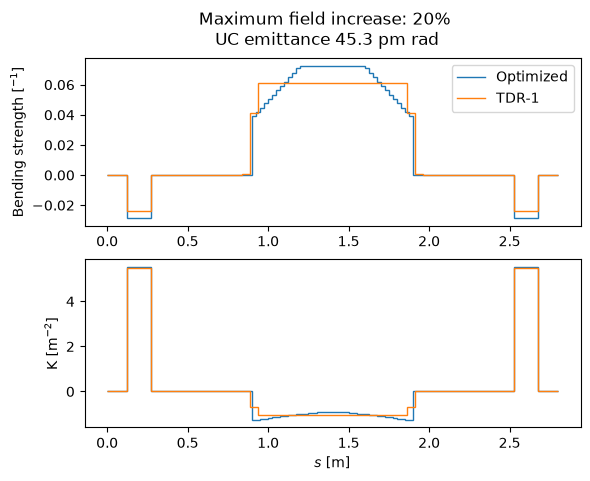

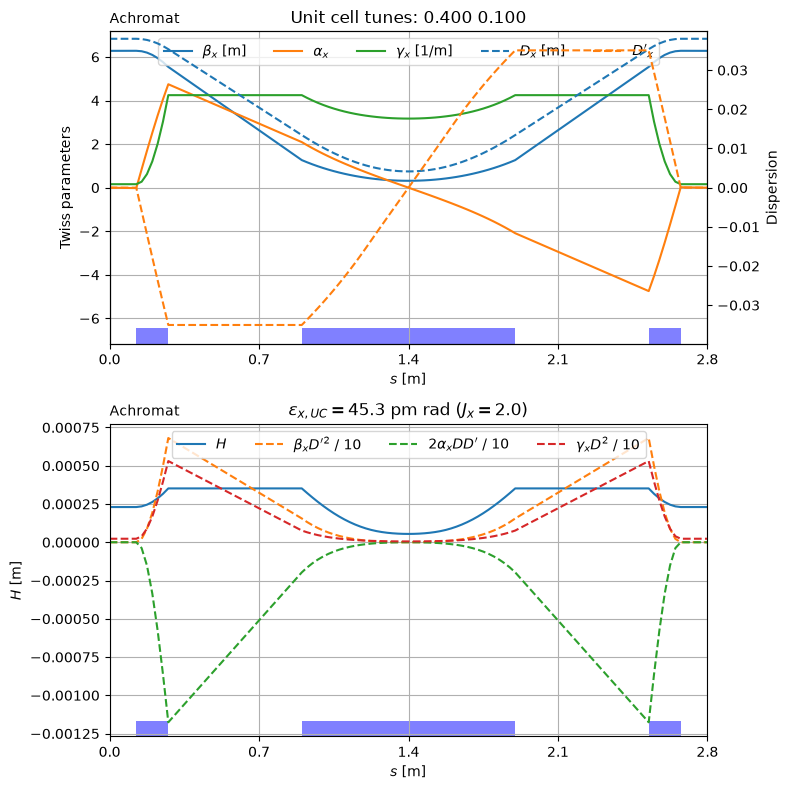

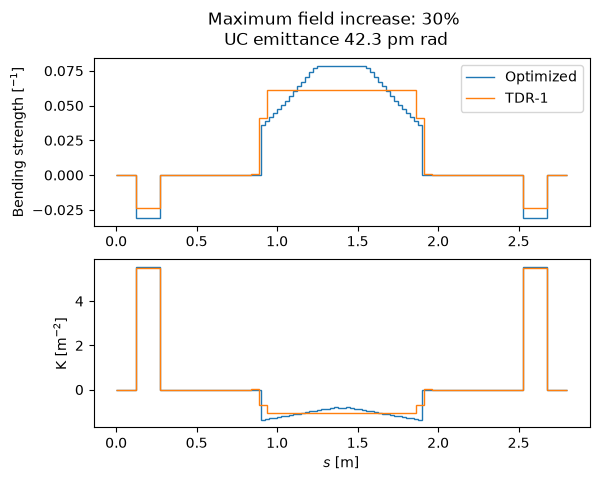

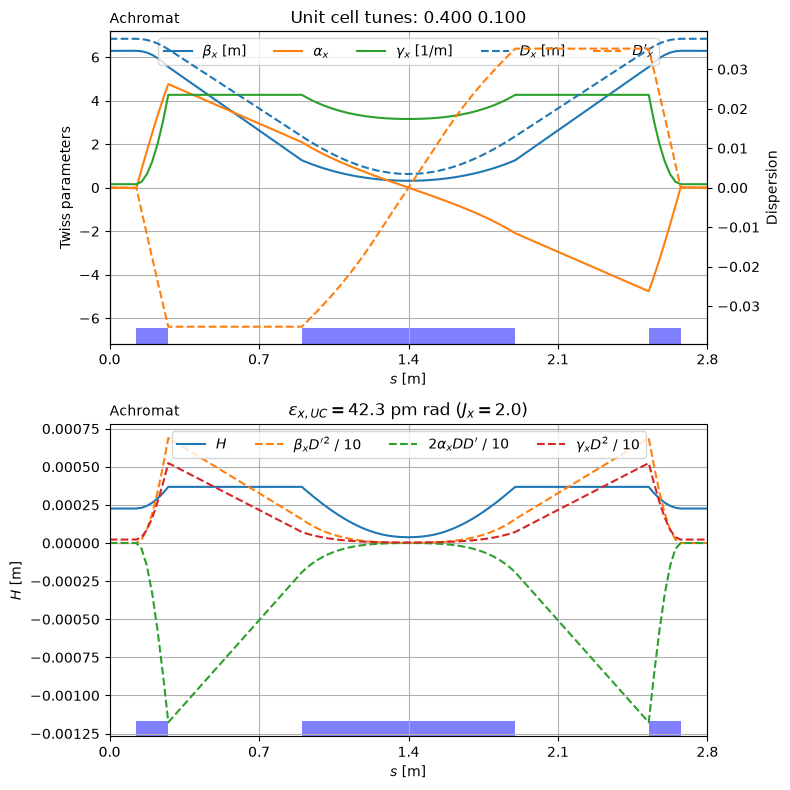

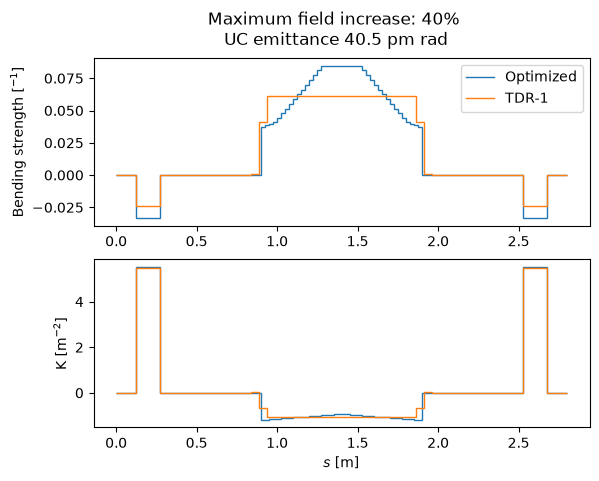

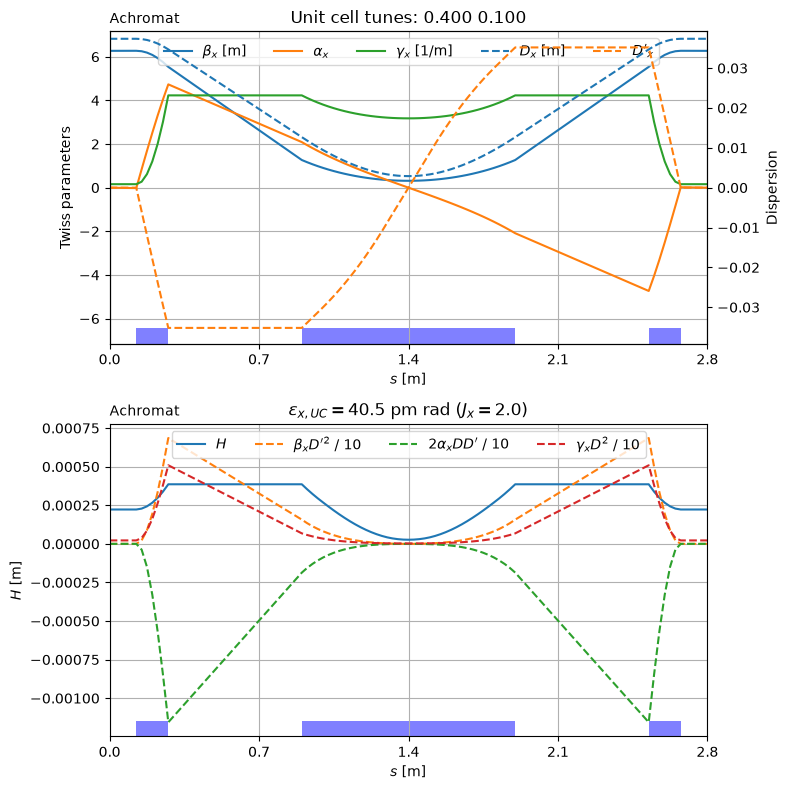

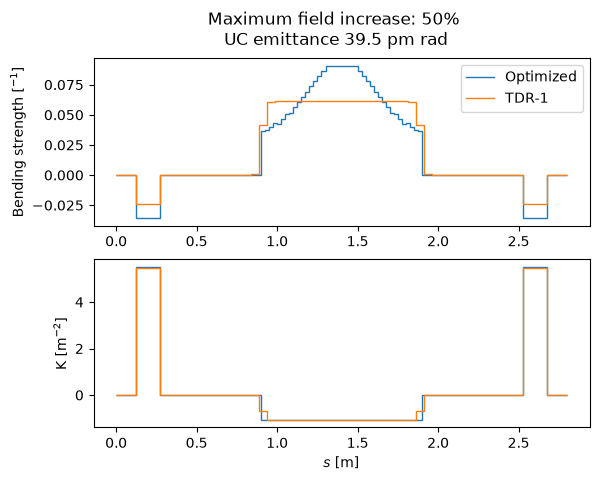

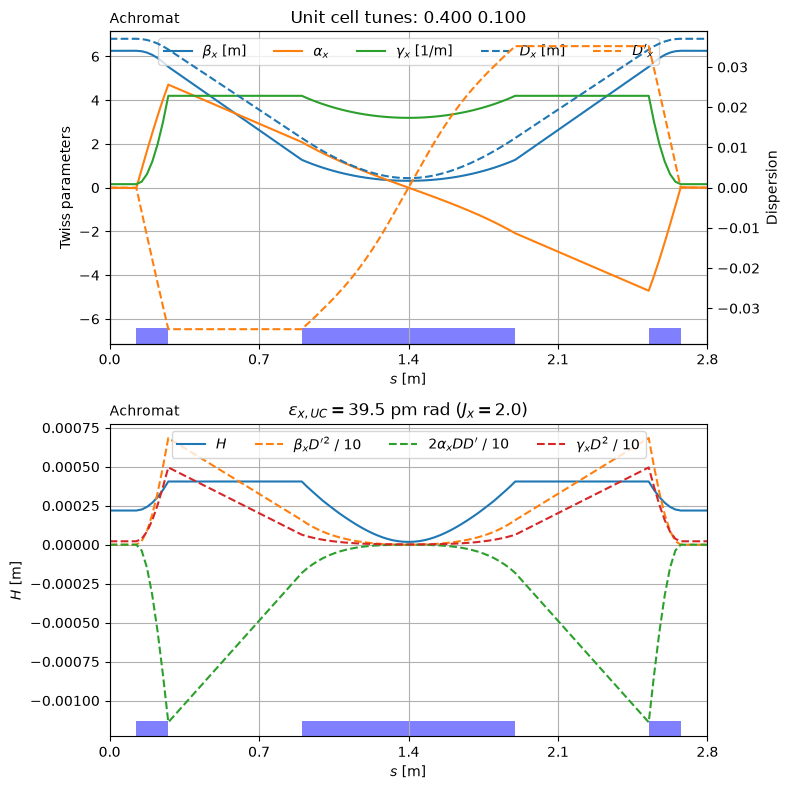

In [253]:
emittances = np.zeros(len(ratio))
for i, (r, UC) in enumerate(zip(ratio, UC_opt)):
    emittances[i] = UC.radiation_parameters().emittances[0]*1e12
    fig, axs = plt.subplots(2, 1)
    utils.plotting.plot_magnet(UC, axs)
    utils.plotting.plot_magnet(UC0, axs)
    fig.suptitle(f'Maximum field increase: {100*(r-1):.0f}%\n UC emittance {emittances[i]:.1f} pm rad')
    axs[0].legend(['Optimized', 'TDR-1'])
    plt.show()

    evaluate_UC(UC)

In [258]:
emittances_ring = np.zeros(len(ratio))
for i, (r, UC) in enumerate(zip(ratio, UC_opt)):
    ring = utils.at.replace_family(ring0, 'D2_v1', UC['D2_v1'], pad=True)
    ring = utils.at.replace_family(ring, 'R1_v1', UC['R1_v1'][0:6], pad=True)
    index_UC = ring.get_uint32_index('UCborder')
    UC_elemdata0 = at.linopt4(UC)[0]

    # For scaling D1 strengths
    D1_refpts = ring.uint32_refpts('D1_v1')
    D1_K0 = np.array([ring[i].K for i in D1_refpts])

    goal_tune = np.array([58.3202, 18.1676]) # TDR-1

    def set_D1_scale(value):
        for i, K0 in zip(D1_refpts, D1_K0):
            ring[i].K = value* K0

    def get_D1_scale(**kwargs):
        return ring[D1_refpts[0]].K / D1_K0[0]

    vars = at.VariableList([
        at.CustomVariable(set_D1_scale, get_D1_scale, name='D1 scale', delta=1e-3),
        at.RefptsVariable('Q1_v1', attrname='K', name='Q1', delta=1e-5),
        at.RefptsVariable('Q2_v1', attrname='K', name='Q2', delta=1e-5),
        at.RefptsVariable('Q3_v1', attrname='K', name='Q2', delta=1e-5),
    ])

    obs = at.ObservableList([
        # Unit cell Twiss matching
        at.LocalOpticsObservable(index_UC, 'alpha', plane='x', target=0, weight=1/len(index_UC)),
        at.LocalOpticsObservable(index_UC, 'alpha', plane='y', target=0, weight=1/len(index_UC)),

        # Unit cell dispersion matching
        at.LocalOpticsObservable(index_UC, 'dispersion', plane=0, target=UC_elemdata0.dispersion[0], weight=1/len(index_UC)),

        # Goal tune
        at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*goal_tune[0]/20),
        at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*goal_tune[1]/20),

        # Dispersion in long straights
        at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
        at.LocalOpticsObservable(0, 'dispersion', plane=1, target=0),
    ])

    try:
        ring.match(vars, obs, verbose=2)
        emittances_ring[i] = ring.radiation_parameters().emittances[0]*1e12
    except:
        emittances_ring[i] = np.nan


22 constraints, 4 variables, using method lm

`ftol` termination condition is satisfied.
Function evaluations 7, initial cost 1.9795e-02, final cost 5.8482e-03, first-order optimality 6.94e-07.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
alpha[x]
    UCborder          0.000363683      -0.000122453               0.0               0.0      -0.000122453 
    UCborder          -0.00355835        0.00119811               0.0               0.0        0.00119811 
    UCborder           -0.0023031       0.000775462               0.0               0.0       0.000775462 
    UCborder            0.0023031      -0.000775462               0.0               0.0      -0.000775462 
    UCborder           0.00355835       -0.00119811               0.0               0.0       -0.00119811 
    UCborder         -0.000363683       0.000122453               0.0               0.0       0.000122453 
alpha[y]
    UCborder          8

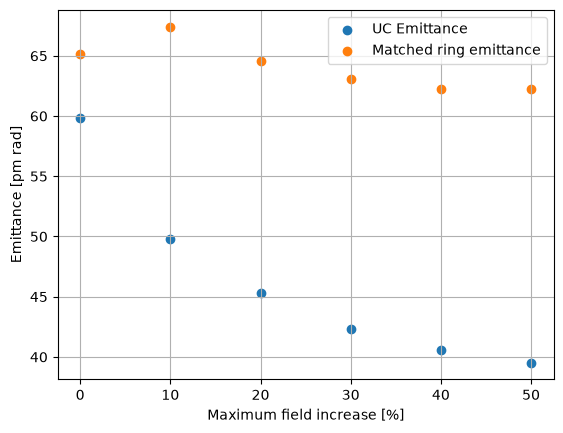

In [255]:
plt.scatter(100*(ratio-1), emittances, label='UC Emittance')
plt.scatter(100*(ratio-1), emittances_ring, label='Matched ring emittance')
plt.grid()
plt.xlabel('Maximum field increase [%]')
plt.ylabel('Emittance [pm rad]')

plt.legend()
plt.show()

## Correct magnet levels

In [259]:
with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
    TDR_1 = pickle.load(file)

In [260]:
def maxabs(x):
    x = np.asanyarray(x)
    return x.flat[abs(x).argmax()]
def minabs(x):
    x = np.asanyarray(x)
    return x.flat[abs(x).argmin()]

def get_bounds(lim_field_R, lim_gradient_R, lim_field_D, lim_gradient_D, n_R=6, n_D=20):
    B_rho = 3e9 / at.constants.clight
    
    bounds = [(None, None)] # No bounds on dfrift length
    bounds += n_R * [(min(lim_field_R)/B_rho, max(lim_field_R)/B_rho)]
    bounds += n_D * [(min(lim_field_D)/B_rho, max(lim_field_D)/B_rho)]

    bounds += n_R * [(min(lim_gradient_R)/B_rho, max(lim_gradient_R)/B_rho)]
    bounds += n_D * [(min(lim_gradient_D)/B_rho, max(lim_gradient_D)/B_rho)]
    return bounds

B_rho = TDR_1.energy / at.constants.clight
print(f'B rho: {B_rho:.2f}')
print()

fam = 'D2_v1'
rho_min = minabs([e.Length / e.BendingAngle for e in UC0[fam]])
K_max = maxabs([e.K for e in UC0[fam]])
B = B_rho / rho_min   # T
G = B_rho * K_max
print('D2')
print(f'Max field: {B:.2f} T')
print(f'Max gradient: {G:.2f} T/m')

fam = 'R1_v1'
rho_min = minabs([e.Length / e.BendingAngle for e in UC0[fam]])
K_max = maxabs([e.K for e in UC0[fam]])
B = B_rho / rho_min   # T
G = B_rho * K_max
print()
print('R2')
print(f'Max field: {B:.2f} T')
print(f'Max gradient: {G:.2f} T/m')

B rho: 10.01

D2
Max field: 0.61 T
Max gradient: -10.67 T/m

R2
Max field: -0.24 T
Max gradient: 54.83 T/m


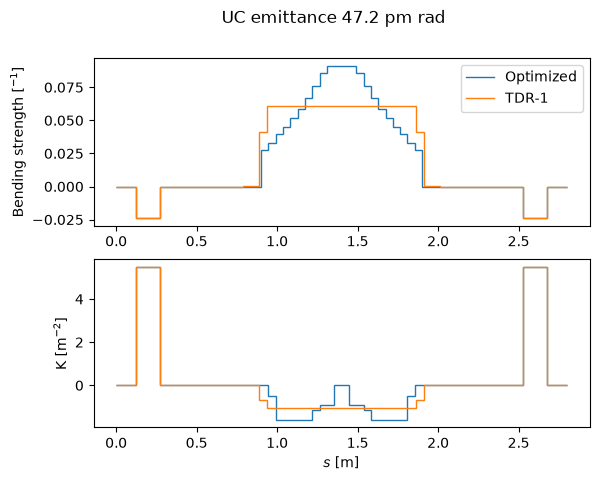

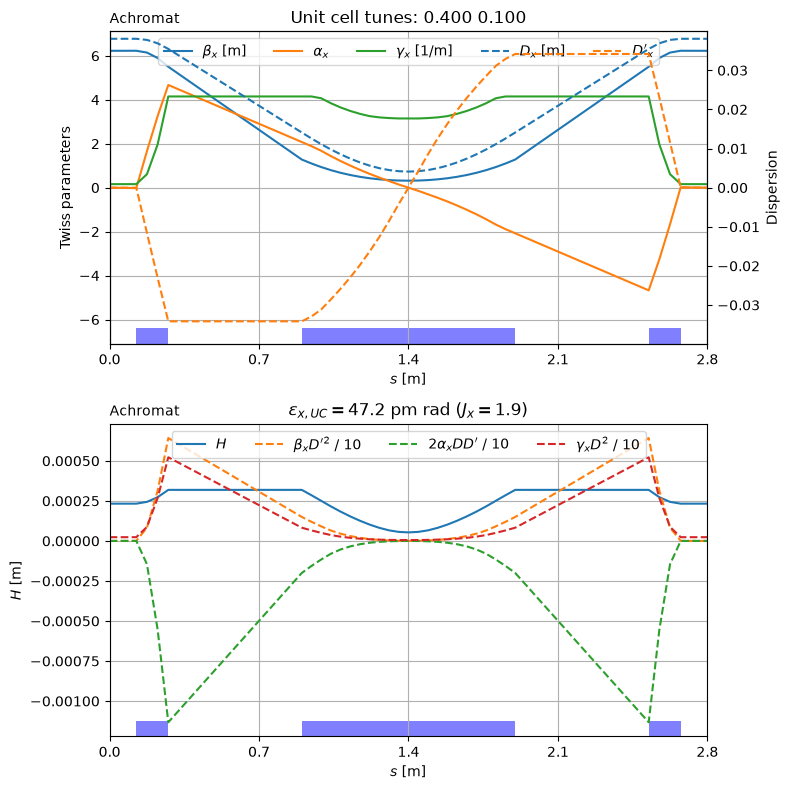

In [264]:
n_R = 3
n_D = 11
L_R = 0.15 # 0.15
L_D = 1.0 # 1.0

bounds = get_bounds(
    lim_field_R   =np.array([0,  -0.24])*1.0,         # Reverse bend field limits [T]         (TDR-1 maximum: -0.24 T)
    lim_gradient_R=np.array([0,  54.83])*1.0,         # Reverse bend gradient limits [T/m]    (TDR-1 maximum:  54.83 T/m)
    lim_field_D   =np.array([0,   0.61])*1.5,         # Dipole bend field limits [T]          (TDR-1 maximum:  0.61 T)
    lim_gradient_D=np.array([0, -10.67])*1.5,         # Dipole bend gradient limits [T/m]     (TDR-1 maximum: -10.67 T/m),
    n_R=n_R,
    n_D=n_D
)    

UC_opt = simplified_UC(UC0, n_R, n_D, L_R, L_D)
result = scipy.optimize.minimize(
    loss,
    get_UC_x(UC_opt),
    args=(UC_opt,),
    constraints={
        'type': 'eq',
        'fun': constraint_fun,
        'args': (UC_opt,),
    },
    bounds = bounds,
    tol=1e-12
)

emittances[i] = UC_opt.radiation_parameters().emittances[0]*1e12
fig, axs = plt.subplots(2, 1)
utils.plotting.plot_magnet(UC_opt, axs)
utils.plotting.plot_magnet(UC0, axs)
fig.suptitle(f'UC emittance {emittances[i]:.1f} pm rad')
axs[0].legend(['Optimized', 'TDR-1'])
plt.show()

evaluate_UC(UC_opt)

In [265]:
ring = utils.at.replace_family(ring0, 'D2_v1', UC_opt['D2_v1'], pad=True)
ring = utils.at.replace_family(ring, 'R1_v1', UC_opt['R1_v1'][0], pad=True)
index_UC = ring.get_uint32_index('UCborder')
UC_elemdata0 = at.linopt4(UC)[0]

# For scaling D1 strengths
D1_refpts = ring.uint32_refpts('D1_v1')
D1_K0 = np.array([ring[i].K for i in D1_refpts])

goal_tune = np.array([58.3202, 18.1676]) # TDR-1

def set_D1_scale(value):
    for i, K0 in zip(D1_refpts, D1_K0):
        ring[i].K = value* K0

def get_D1_scale(**kwargs):
    return ring[D1_refpts[0]].K / D1_K0[0]

vars = at.VariableList([
    at.CustomVariable(set_D1_scale, get_D1_scale, name='D1 scale', delta=1e-3),
    at.RefptsVariable('Q1_v1', attrname='K', name='Q1', delta=1e-5),
    at.RefptsVariable('Q2_v1', attrname='K', name='Q2', delta=1e-5),
    at.RefptsVariable('Q3_v1', attrname='K', name='Q2', delta=1e-5),
])

obs = at.ObservableList([
    # Unit cell Twiss matching
    at.LocalOpticsObservable(index_UC, 'alpha', plane='x', target=0, weight=1/len(index_UC)),
    at.LocalOpticsObservable(index_UC, 'alpha', plane='y', target=0, weight=1/len(index_UC)),

    # Unit cell dispersion matching
    at.LocalOpticsObservable(index_UC, 'dispersion', plane=0, target=UC_elemdata0.dispersion[0], weight=1/len(index_UC)),

    # Goal tune
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*goal_tune[0]/20),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*goal_tune[1]/20),

    # Dispersion in long straights
    at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
    at.LocalOpticsObservable(0, 'dispersion', plane=1, target=0),
])

ring.match(vars, obs, verbose=2)

print(at.radiation_parameters(ring).emittances[0])

AtError: Evaluation of alpha[x] failed: Unstable ring

In [ ]:
fig, axs = plt.subplots(1, 2)
utils.plotting.plot_magnet(UC0, axs)
utils.plotting.plot_magnet(UC_simple, axs)

In [ ]:
# Constant reverse bends, constant positive bends
D_shape = np.ones(26)
D_shape[0:6] = -1/2.5 # Roughly the same as TDR-1

K_values = np.ones(26)
K_values[0:6] = UC0['R1_v1'][0].K
K_values[6:] = UC0['D2_v1'][7].K
UC = get_freeform_UC(UC0, [0.4, 0.1], D_shape, K_values)

evaluate_UC(UC)

In [ ]:
def loss(x, UC0, tunes):
    D_shape = x[:len(x)//2]
    K_value = x[len(x)//2:]

    try:
        UC = get_freeform_UC(UC0, tunes, D_shape, K_value, 6, 20)
        emittance = 1e12 * UC.radiation_parameters().emittances[0]
    except:
        return 1000
    
    return emittance

# Constant reverse bends, constant positive bends
D_shape = np.ones(26)
D_shape[0:6] = -1/2.5 # Roughly the same as TDR-1

K_value = np.ones(26)
K_value[0:6] = UC0['R1_v1'][0].K
K_value[6:] = UC0['D2_v1'][7].K

tunes = np.array([0.4, 0.1])

res = scipy.optimize.minimize(
    fun=loss,
    x0=np.hstack([D_shape, K_value]),
    args=(UC0, tunes),
)

print(res)

## Interpolation

In [ ]:
def loss(x, UC, n_R. n_D, interpolation=1):
    L_inner = x[0]
    rho_inv = x[1:][:len(x[1:])//2]
    K = x[1:][len(x[1:])//2:]

    rho_inv


    # Set drift length
    for e in UC['drift_inner']:
        e.Length = L_inner

    # Set fields
    set_UC_fields(UC, rho_inv, K)

    try:
        emittance = 1e12 * UC.radiation_parameters().emittances[0]
    except Exception as e:
        return 1000
    
    return emittance

def constraints(x, UC):
    L_inner = x[0]
    angles = x[1:][:len(x[1:])//2]
    K_values = x[1:][len(x[1:])//2:]

    # Set drift length
    for e in UC['drift_inner']:
        e.Length = L_inner

    # Set fields
    set_UC_fields(UC, angles, K_values)

    # Geometric constraints
    geometry = UC.get_geometry(at.End)[0]
    x_end = geometry.x[0]
    theta_UC = geometry.angle[0]

    # Phase
    UC_tunes = UC.linopt4(at.End)[2].mu[0] / (2*np.pi)

    return x_end, theta_UC, *UC_tunes

def constraint_fun(x, UC):
    return np.asarray(constraints(x, UC)) - np.array([
        UC0.get_geometry(at.End)[0].x[0],
        UC0.get_geometry(at.End)[0].angle[0],
        0.4,
        0.1,
    ])